In [1]:
import pandas as pd
import polars as pl

df = pd.read_csv("amz_uk_price_prediction_dataset.csv")

In [2]:
df.describe()

,uid,stars,reviews,price,boughtInLastMonth
count,2.443651e+06,2.443651e+06,2.443651e+06,2.443651e+06,2.443651e+06
mean,1.370545e+06,2.152836e+00,4.806278e+02,8.924381e+01,2.589699e+01
std,8.160562e+05,2.194865e+00,5.944124e+03,3.456089e+02,2.404837e+02
min,1.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00
25%,6.589215e+05,0.000000e+00,0.000000e+00,9.990000e+00,0.000000e+00
50%,1.349029e+06,0.000000e+00,0.000000e+00,1.909000e+01,0.000000e+00
75%,2.060686e+06,4.400000e+00,5.900000e+01,4.599000e+01,0.000000e+00
max,2.828593e+06,5.000000e+00,1.356658e+06,1.000000e+05,5.000000e+04


In [3]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2443651 entries, 0 to 2443650
Data columns (total 9 columns):
 #   Column             Dtype  
---  ------             -----  
 0   uid                int64  
 1   asin               object 
 2   title              object 
 3   stars              float64
 4   reviews            int64  
 5   price              float64
 6   isBestSeller       bool   
 7   boughtInLastMonth  int64  
 8   category           object 
dtypes: bool(1), float64(2), int64(3), object(3)
memory usage: 151.5+ MB


In [4]:
df.columns

Index(['uid', 'asin', 'title', 'stars', 'reviews', 'price', 'isBestSeller',
       'boughtInLastMonth', 'category'],
      dtype='object')

In [5]:
df.null_count()

AttributeError: 'DataFrame' object has no attribute 'null_count'

In [6]:
# Frequency table for the product category
frequency_table = df['category'].value_counts()
print(frequency_table)

category
Sports & Outdoors                         836265
Beauty                                     19312
Handmade Clothing, Shoes & Accessories     19229
Bath & Body                                19092
Birthday Gifts                             18978
                                           ...  
Alexa Built-In Devices                       107
Motorbike Chassis                            107
Plugs                                        107
Smart Home Security & Lighting               104
Smart Speakers                                54
Name: count, Length: 296, dtype: int64


In [7]:
#top 5 most listed product categories
top_5_categories = frequency_table.head(5)

print(top_5_categories)

category
Sports & Outdoors                         836265
Beauty                                     19312
Handmade Clothing, Shoes & Accessories     19229
Bath & Body                                19092
Birthday Gifts                             18978
Name: count, dtype: int64


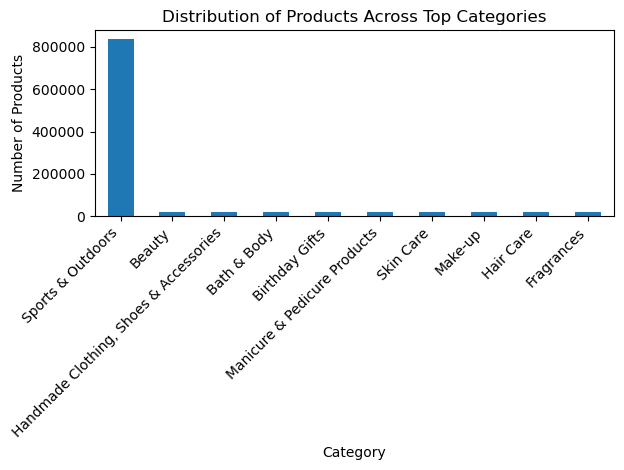

In [9]:
#Display the distribution of products across different categories using a bar chart
import matplotlib.pyplot as plt
top_n = 10
top_categories = frequency_table.head(top_n)

plt.figure()
top_categories.plot(kind='bar')
plt.xlabel('Category')
plt.ylabel('Number of Products')
plt.title('Distribution of Products Across Top Categories')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

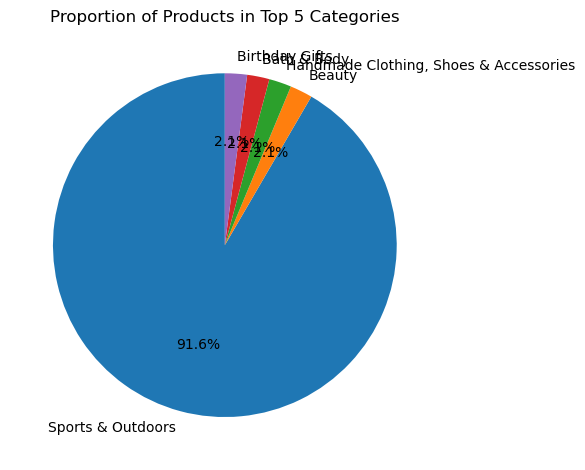

In [10]:
#For a subset of top categories, visualize their proportions using a pie chart

# Get top 5 categories
top_categories = df['category'].value_counts().head(5)

# Plot pie chart
plt.figure()
top_categories.plot(
    kind='pie',
    autopct='%1.1f%%',
    startangle=90
)
plt.ylabel('')
plt.title('Proportion of Products in Top 5 Categories')
plt.tight_layout()
plt.show()

In [11]:
#mean, median, and mode for the price of products.

mean_price = df['price'].mean()
median_price = df['price'].median()
mode_price = df['price'].mode()[0]

mean_price, median_price, mode_price

(89.24380943923663, 19.09, 9.99)

In [12]:
print(f"Average price: {mean_price:.2f}")

Average price: 89.24


In [13]:
print(f"Most common price (mode): {mode_price:.2f}")

Most common price (mode): 9.99


What's the average price point of products listed? How does this compare with the most common price point (mode)?

The average price of the products listed is 89.24, which is much larger than the mode price which is 9.99. Aparently there might be product prices that are creating this big discrepancy.

Determine the variance, standard deviation, range, and interquartile range for product price.

In [17]:
#variance, standard deviation, range, and interquartile range for product price

variance_price = df['price'].var()
std_dev_price = df['price'].std()
min_price = df['price'].min()
max_price = df['price'].max()
range_price = max_price - min_price

quantiles_price = df['price'].quantile([0.25, 0.5, 0.75])


In [18]:
variance_price, std_dev_price, min_price, max_price, range_price, quantiles_price

(119445.48532256528,
 345.60886175352226,
 0.0,
 100000.0,
 100000.0,
 0.25     9.99
 0.50    19.09
 0.75    45.99
 Name: price, dtype: float64)

How varied are the product prices? Are there any indicators of a significant spread in prices?


In [ ]:
Is there a specific price range where most products fall? Plot a histogram to visualize the distribution of product prices. If its hard to read these diagrams, think why this is, and explain how it could be solved..

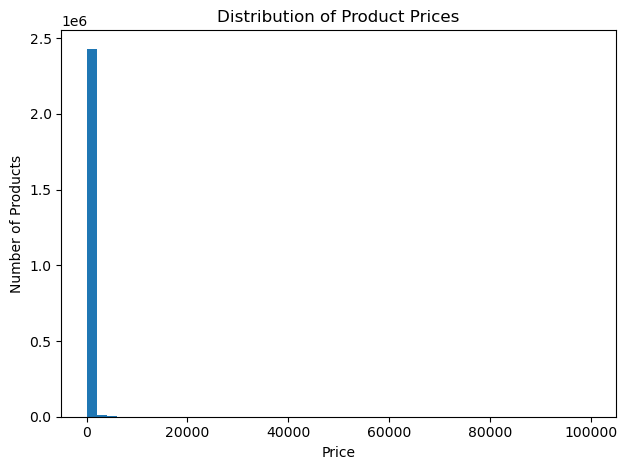

In [20]:
plt.figure()
df['price'].plot(kind='hist', bins=50)
plt.xlabel('Price')
plt.ylabel('Number of Products')
plt.title('Distribution of Product Prices')
plt.tight_layout()
plt.show()

Are there products that are priced significantly higher than the rest? Use a box plot to showcase the spread and potential outliers in product pricing.

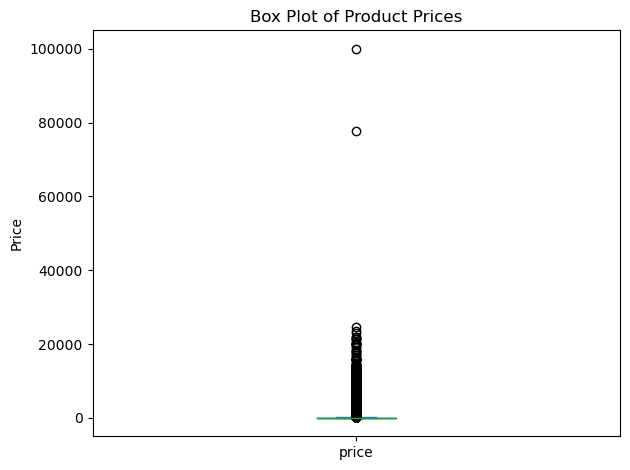

In [21]:
plt.figure()
df['price'].plot(kind='box')
plt.ylabel('Price')
plt.title('Box Plot of Product Prices')
plt.tight_layout()
plt.show()

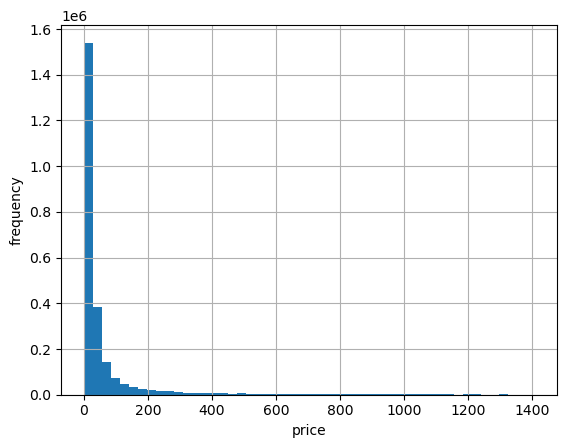

In [23]:
#exclude the worst price outliers using a high quantile cutoff
upper = df["price"].quantile(0.99)
filtered = df[df["price"] <= upper]

filtered["price"].hist(bins=50)
plt.xlabel("price")
plt.ylabel("frequency")
plt.show()

Calculate the mean, median, and mode for the rating of products.
How do customers generally rate products? Is there a common trend?

In [25]:
mean_rating = df['stars'].mean()
print(f"Mean rating: {mean_rating:.2f}")

Mean rating: 2.15


In [26]:
median_rating = df['stars'].median()
print(f"Median rating: {median_rating:.2f}")

Median rating: 0.00


In [27]:
mode_rating = df['stars'].mode()[0]
print(f"Mode rating: {mode_rating}")

Mode rating: 0.0


In [ ]:
We see that the median and mode rating of customers is 0, something expected as usually the people who want to write reviews are the people who are very dissatisfied with the product.

Determine the variance, standard deviation, and interquartile range for product rating.
Are the ratings consistent, or is there a wide variation in customer feedback?

In [30]:
#variance, standard deviation, range, and interquartile range for rating

variance_rating = df['stars'].var()
std_dev_rating = df['stars'].std()
min_rating = df['stars'].min()
max_rating = df['stars'].max()
range_rating = max_price - min_price

quantiles_rating = df['stars'].quantile([0.25, 0.5, 0.75])

In [31]:
variance_rating, std_dev_rating, min_rating, max_rating, range_rating, quantiles_rating

(4.81743402976196,
 2.1948653785054697,
 0.0,
 5.0,
 5.0,
 0.25    0.0
 0.50    0.0
 0.75    4.4
 Name: stars, dtype: float64)

The customer ratings are not consistent. Most products have no ratings (0), while a small number of products receive high ratings, resulting in a high variance and standard deviation. This indicates a wide variation in customer feedback.

Calculate the skewness and kurtosis for the rating column.
Are the ratings normally distributed, or do they lean towards higher or lower values?

In [33]:
skewness_rating = df['stars'].skew()
kurtosis_rating = df['stars'].kurtosis()

skewness_rating, kurtosis_rating

(0.08120735761080985, -1.9260061280432985)

The ratings are not normally distributed. The majority of products have a rating of 0, while a smaller number of products have high ratings, creating a right-skewed distribution with a flat overall shape (negative kurtosis). This indicates that customer feedback is concentrated at the lower end, with only a few products receiving high ratings.

Plot a histogram to visualize the distribution of product ratings. Is there a specific rating that is more common?

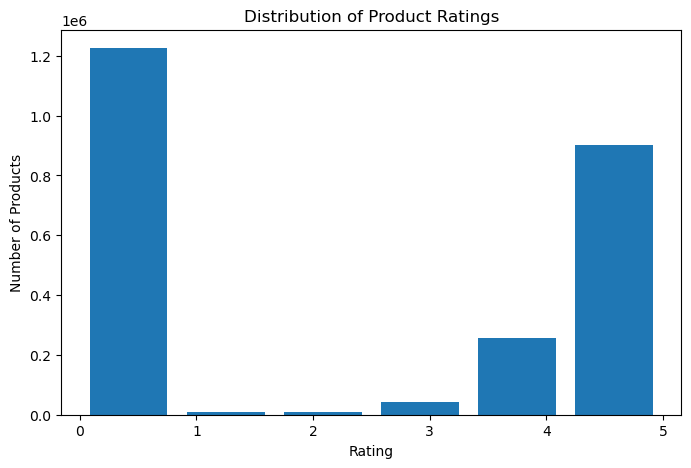

In [34]:
plt.figure(figsize=(8,5))
df['stars'].plot(kind='hist', bins=6, rwidth=0.8)  # bins=6 for ratings 0–5
plt.xlabel('Rating')
plt.ylabel('Number of Products')
plt.title('Distribution of Product Ratings')
plt.xticks(range(6))  # 0,1,2,3,4,5
plt.show()